# 04 — Interpretacja modelu finalnego (SHAP)

`shap.TreeExplainer` na 2000 losowych wierszach z `test_in`. Wartości SHAP kolumn one-hot
i par sin/cos są **sumowane do cech oryginalnych** (SHAP jest addytywny), więc np. `County`
to jedna pozycja, a nie kilkadziesiąt.

SHAP opisuje działanie modelu, nie przyczyny wypadków. Wysoka pozycja `Source` oznacza,
że model w dużej mierze uczy się sposobu etykietowania danego dostawcy.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.precision', 3)
import joblib
from src.experiment import load_all, RESULTS_DIR
from src.final import FINAL_MODEL_PATH
from src.explain import shap_values_by_feature, importance_table
from src import plots

df = load_all()
sample = df[df['split'] == 'test_in'].sample(n=2000, random_state=42)
model = joblib.load(FINAL_MODEL_PATH)
shap_by_class = shap_values_by_feature(model, sample)
importance = importance_table(shap_by_class)
importance.to_csv(f'{RESULTS_DIR}/shap_importance.csv')
importance.head(15)

,Sev1-2,Sev3,Sev4,mean_all_classes
Source,0.422,1.019,1.507,0.983
road_type,0.289,0.425,0.150,0.288
Wind_Speed(mph),0.257,0.350,0.102,0.237
Start_Lng,0.189,0.249,0.136,0.192
Month,0.148,0.221,0.139,0.169
Start_Lat,0.139,0.192,0.152,0.161
Hour,0.061,0.083,0.213,0.119
Pressure(in),0.094,0.123,0.132,0.116
Wind_Direction_Mapped,0.089,0.087,0.068,0.081
County,0.084,0.089,0.064,0.079


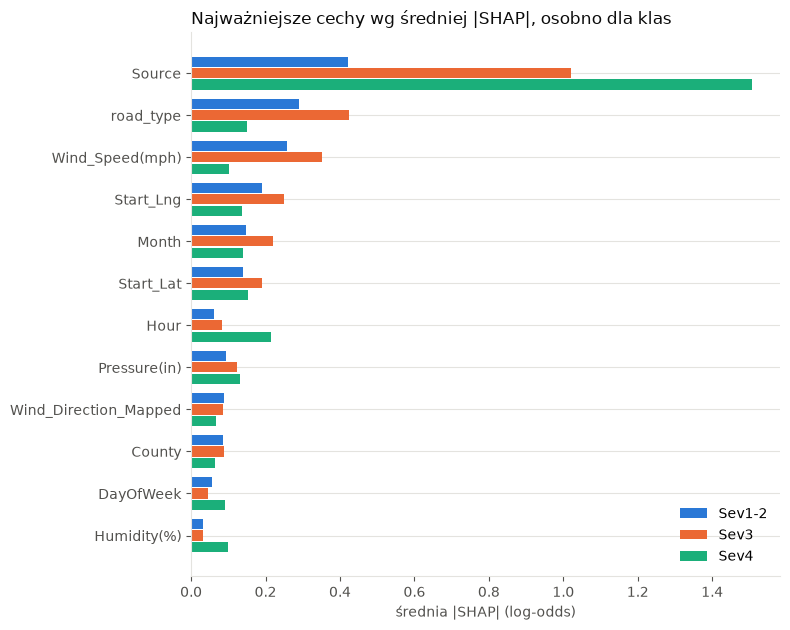

In [2]:
fig = plots.importance_by_class(importance, top=12, title='Najważniejsze cechy wg średniej |SHAP|, osobno dla klas')

**Uwaga do interpretacji.** `Wind_Speed(mph)` ma 9,4% braków, a ich częstość może zależeć
od okresu i stacji pogodowej — wysoka pozycja tej cechy może więc częściowo odzwierciedlać czas
lub źródło, a nie wpływ wiatru. To hipoteza do sprawdzenia, nie wniosek.